# LankaEcon – Phase 3: Economic Relationship Analysis

**Questions**
1. **Lead/lag:** how quickly do exchange-rate, world-price and fuel-cost movements show up in Sri Lankan prices?
2. **Granger causality & VAR:** which series help predict which, and how do prices respond to shocks over time (impulse responses)?
3. **Pass-through:** what share of a change in the exchange rate or a world benchmark reaches domestic prices, and did it change after the 2022 float and crisis?

**Conventions**
- Growth rates are **100 × monthly log-changes** (≈ % change), so regression coefficients are **elasticities**.
- Inflation uses the **cleaned CPI** from Phase 1 (`inflation_mom_pct`); the raw IMF series is never used. `ccpi_basis` (1 for CCPI-based months, 0 for NCPI-based months) is a control, and the `cpi_break_flag` months use official DCS values.
- Fuel months flagged `possible_missing_revision` are excluded.
- **Regime controls:** `covid` (2020-03 → 2021-12), `crisis` (2022-01 → 2023-06), `post_float` (from 2022-03).

Analysis code lives in `src/relationships.py`; figures go to `reports/figures/` and summary tables to `reports/tables/`.

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "relationships.py").exists())
sys.path.insert(0, str(ROOT / "src"))
import relationships as R

warnings.filterwarnings("ignore")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
FIG, TAB = ROOT / "reports" / "figures", ROOT / "reports" / "tables"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 130, "axes.titleweight": "bold"})
save = lambda fig, name: fig.savefig(FIG / f"{name}.png", bbox_inches="tight")

df = R.load_monthly()
D = lambda c: R.dlog(df[c])          # 100 x monthly log change
print(df.shape, f"{df.index.min():%Y-%m} → {df.index.max():%Y-%m}")

(323, 42) 2000-01 → 2026-11


## 1. Samples, coverage and truncated series

In [2]:
cols = ["lkr_per_usd", "cpi_headline_index", "inflation_mom_pct", "world_brent_usd_bbl", "world_food_price_index",
        "world_rice_usd_mt", "world_wheat_usd_mt", "world_sugar_usd_lb", "world_coconut_oil_usd_mt",
        "wfp_rice_white", "wfp_wheat_flour", "wfp_sugar", "wfp_lentils", "wfp_big_onion_imp", "wfp_coconut",
        "cbsl_sugar", "cbsl_dhal", "cbsl_big_onion_imp", "cbsl_potato_imp", "cbsl_coconut", "cbsl_rice_nadu",
        "fuel_auto_diesel", "fuel_petrol_92"]
cov = R.coverage(df, cols)
display(cov)
print("Inflation basis by month:", df["inflation_source"].value_counts().to_dict())

,first,last,n_months,gaps,longest_unbroken,longest_len
series,,,,,,
lkr_per_usd,2000-01,2026-10,322,0,2000-01..2026-10,322
cpi_headline_index,2000-01,2026-08,320,0,2000-01..2026-08,320
inflation_mom_pct,2000-01,2026-08,320,0,2000-01..2026-08,320
world_brent_usd_bbl,2000-01,2026-10,322,0,2000-01..2026-10,322
world_food_price_index,2000-01,2026-10,322,0,2000-01..2026-10,322
world_rice_usd_mt,2010-05,2026-10,198,0,2010-05..2026-10,198
world_wheat_usd_mt,2000-01,2026-10,322,0,2000-01..2026-10,322
world_sugar_usd_lb,2000-01,2026-10,322,0,2000-01..2026-10,322
world_coconut_oil_usd_mt,2000-01,2026-10,322,0,2000-01..2026-10,322


Inflation basis by month: {'imf_ncpi': 287, 'dcs_ccpi': 23, 'imf_ccpi': 10}


**Three analysis samples follow from this coverage:**

| Sample | Period | Months | Series |
|---|---|---|---|
| **A – macro** | 2000-02 → 2026-08 | ~318 | CPI inflation (cleaned), LKR/USD, Brent, world food index |
| **B – long commodity** | 2006-02 → 2022-06 (rice from 2010-06) | 143–197 | WFP wheat flour, WFP white rice, world wheat/rice |
| **C – recent CBSL** | 2023-02 → 2026-10 | 45 | CBSL retail sugar, dhal, big onion, potato (imp.), coconut, Nadu rice |

**Truncated or missing series (reported, not hidden):**
- **Wheat flour (WFP)** ends in **2022-06**, at the peak of the crisis, so post-crisis behaviour can't be estimated.
- **Sugar:** WFP has only 61 scattered months (longest unbroken run 31) and ends 2022-06. CBSL starts 2023-01, so **the two never overlap**. Sugar is analysed on the CBSL sample only.
- **Lentils, big onion, coconut (WFP)** have gaps in 2021–22, so the recent CBSL versions are used instead.
- **World rice** benchmark (IMF `PRICENPQ`) starts 2010-05.
- **Fuel:** retail diesel/petrol exist only for 2015-09 → 2018-03 (WFP) and scattered 2023–2026 months (DCS + CPC log, unflagged). There are about 48 usable monthly changes for diesel, too few and too gappy for a VAR. Fuel is analysed with pairwise correlations and a small regression; **Brent in LKR** stands in for fuel costs in the VARs.
- **Interest rates** (IMF) stop in 2020-05 and are not used.

## 2. Lead/lag correlations

`corr(x_{t−k}, y_t)` for k = 0…6 months. A **positive k means the driver leads** the domestic price. Each cell uses all overlapping months, and N is shown. The 95% significance band is ±1.96/√N.

,driver,target,best_lag,corr,n,significant_95
0,ΔLKR/USD,CPI inflation m/m,1,0.514,318,True
1,ΔLKR/USD,ΔWheat flour (WFP),0,0.327,219,True
2,ΔLKR/USD,ΔRice white (WFP),1,0.220,218,True
3,ΔBrent (USD),CPI inflation m/m,4,0.145,315,True
4,ΔBrent (USD),ΔWheat flour (WFP),2,0.182,219,True
5,ΔBrent (USD),ΔRice white (WFP),0,0.099,218,False
6,ΔWorld food index,CPI inflation m/m,2,0.275,317,True
7,ΔWorld food index,ΔWheat flour (WFP),0,0.182,219,True
8,ΔWorld food index,ΔRice white (WFP),0,0.195,218,True


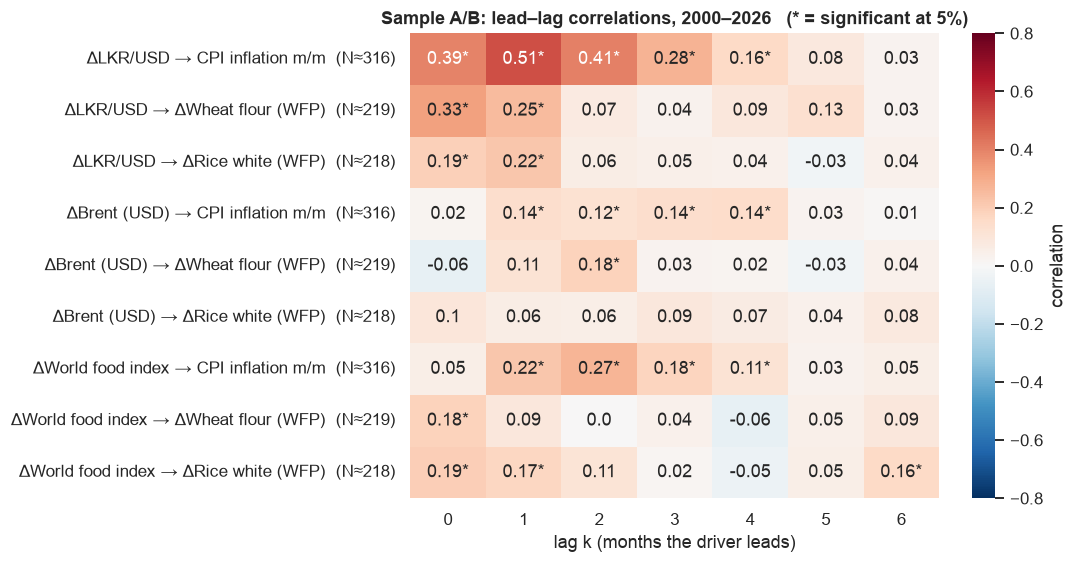

In [3]:
def ccf_heatmap(drivers, targets, title, fname, lags=range(0, 7)):
    corr, nobs, best = R.ccf_grid(drivers, targets, lags)
    crit = 1.96 / np.sqrt(nobs)
    annot = corr.round(2).astype(str) + np.where(corr.abs() > crit, "*", "")
    fig, ax = plt.subplots(figsize=(10, 0.42 * len(corr) + 1.5))
    sns.heatmap(corr.astype(float), cmap="RdBu_r", center=0, vmin=-0.8, vmax=0.8, annot=annot, fmt="",
                cbar_kws={"label": "correlation"}, ax=ax)
    ax.set_yticklabels([f"{d} → {t}  (N≈{int(nobs.loc[(d, t)].median())})" for d, t in corr.index], rotation=0)
    ax.set_xlabel("lag k (months the driver leads)"); ax.set_ylabel("")
    ax.set_title(title + "   (* = significant at 5%)")
    fig.tight_layout(); save(fig, fname)
    return best

long_drivers = {"ΔLKR/USD": D("lkr_per_usd"), "ΔBrent (USD)": D("world_brent_usd_bbl"),
                "ΔWorld food index": D("world_food_price_index")}
long_targets = {"CPI inflation m/m": df["inflation_mom_pct"], "ΔWheat flour (WFP)": D("wfp_wheat_flour"),
                "ΔRice white (WFP)": D("wfp_rice_white")}
best_long = ccf_heatmap(long_drivers, long_targets, "Sample A/B: lead–lag correlations, 2000–2026", "14_ccf_long")
display(best_long.round(3))

,driver,target,best_lag,corr,n,significant_95
0,ΔLKR/USD,ΔSugar,6,-0.444,40,True
1,ΔLKR/USD,ΔRed dhal,3,0.454,43,True
2,ΔLKR/USD,ΔBig onion (imp),6,-0.227,40,False
3,ΔLKR/USD,ΔPotato (imp),2,-0.258,44,False
4,ΔLKR/USD,ΔCoconut,6,-0.183,40,False
5,ΔLKR/USD,ΔRice Nadu,6,-0.489,40,True
6,ΔLKR/USD,ΔDiesel (retail),1,0.479,25,True
7,ΔBrent (LKR),ΔSugar,1,0.305,45,True
8,ΔBrent (LKR),ΔRed dhal,1,0.544,45,True
9,ΔBrent (LKR),ΔBig onion (imp),5,0.211,41,False


Caution: the 'best lag' is chosen after looking at 7 lags with N≈40–45, so some 'significant' results
(especially isolated negative correlations at lag 5–6) are likely false positives.


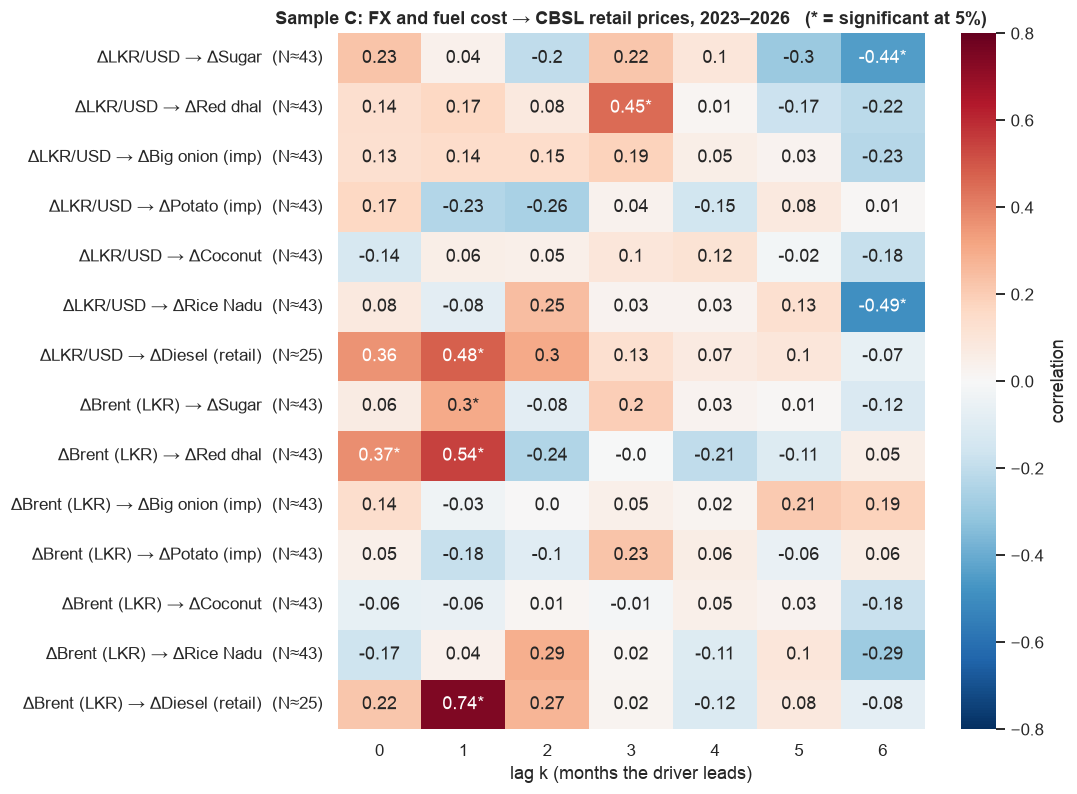

In [4]:
recent = slice("2023-01-01", "2026-10-01")
rd = lambda c: D(c).loc[recent]
recent_drivers = {"ΔLKR/USD": rd("lkr_per_usd"), "ΔBrent (LKR)": rd("world_brent_lkr"),
                  "ΔWorld sugar (USD)": rd("world_sugar_usd_lb"), "ΔWorld rice (USD)": rd("world_rice_usd_mt"),
                  "ΔWorld coconut oil (USD)": rd("world_coconut_oil_usd_mt")}
recent_targets = {"ΔSugar": rd("cbsl_sugar"), "ΔRed dhal": rd("cbsl_dhal"), "ΔBig onion (imp)": rd("cbsl_big_onion_imp"),
                  "ΔPotato (imp)": rd("cbsl_potato_imp"), "ΔCoconut": rd("cbsl_coconut"), "ΔRice Nadu": rd("cbsl_rice_nadu"),
                  "ΔDiesel (retail)": rd("fuel_auto_diesel")}
# FX and fuel cost are tested against every item; world benchmarks only against their matching item.
best_fx_fuel = ccf_heatmap({k: v for k, v in recent_drivers.items() if k in ("ΔLKR/USD", "ΔBrent (LKR)")},
                           recent_targets, "Sample C: FX and fuel cost → CBSL retail prices, 2023–2026", "15_ccf_recent")
_, _, best_all = R.ccf_grid(recent_drivers, recent_targets)
keep = {("ΔWorld sugar (USD)", "ΔSugar"), ("ΔWorld rice (USD)", "ΔRice Nadu"), ("ΔWorld coconut oil (USD)", "ΔCoconut")}
best_world = best_all[[(d, t) in keep for d, t in zip(best_all["driver"], best_all["target"])]]
display(pd.concat([best_fx_fuel, best_world], ignore_index=True).round(3))
print("Caution: the 'best lag' is chosen after looking at 7 lags with N≈40–45, so some 'significant' results")
print("(especially isolated negative correlations at lag 5–6) are likely false positives.")

In [5]:
# Fuel: Brent in LKR vs retail diesel, pooling both periods with retail fuel data (2015-18, 2023-26)
fuel_ccf = R.ccf(D("world_brent_lkr"), D("fuel_auto_diesel"), range(0, 7))
display(fuel_ccf.T)
print("Diesel monthly changes available by year:", D("fuel_auto_diesel").dropna().index.year.value_counts().sort_index().to_dict())

lag,0,1,2,3,4,5,6
corr,0.107,0.470,0.110,0.036,0.085,0.023,0.014
n,47.000,48.000,48.000,48.000,48.000,48.000,48.000
crit_95,0.286,0.283,0.283,0.283,0.283,0.283,0.283


Diesel monthly changes available by year: {2015: 3, 2016: 4, 2017: 12, 2018: 3, 2023: 5, 2024: 10, 2025: 3, 2026: 8}


## 3. Stationarity

ADF (H0: unit root) and KPSS (H0: stationary). A series is called *stationary* when ADF rejects and KPSS does not.

In [6]:
ur_in = {}
for c in ["lkr_per_usd", "cpi_headline_index", "world_brent_usd_bbl", "world_food_price_index", "world_wheat_usd_mt",
          "world_rice_usd_mt", "wfp_wheat_flour", "wfp_rice_white"]:
    ur_in[f"log {c}"] = np.log(df[c])
    ur_in[f"Δlog {c}"] = D(c)
ur_in["inflation_mom_pct"] = df["inflation_mom_pct"]
for c in ["cbsl_sugar", "cbsl_dhal", "cbsl_big_onion_imp", "cbsl_coconut", "cbsl_rice_nadu"]:
    ur_in[f"log {c}"] = np.log(df[c]).loc[recent]
    ur_in[f"Δlog {c}"] = D(c).loc[recent]
ur = R.unit_root_table(ur_in)
display(ur)

,n,adf_p,kpss_p,verdict
series,,,,
log lkr_per_usd,322,0.928,0.010,non-stationary
Δlog lkr_per_usd,321,0.000,0.100,stationary
log cpi_headline_index,320,0.911,0.010,non-stationary
Δlog cpi_headline_index,319,0.000,0.100,stationary
log world_brent_usd_bbl,322,0.127,0.010,non-stationary
Δlog world_brent_usd_bbl,321,0.000,0.100,stationary
log world_food_price_index,322,0.349,0.010,non-stationary
Δlog world_food_price_index,321,0.000,0.100,stationary
log world_wheat_usd_mt,322,0.090,0.010,non-stationary


All price **levels are non-stationary** and all **monthly log-changes are stationary** (the short CBSL changes are mostly stationary or mixed). VARs and pass-through regressions are therefore estimated in **log-differences**, and long-run level relationships are checked with Engle-Granger cointegration tests (Section 5).

## 4. Granger causality and VAR models

**Recursive (Cholesky) ordering, most exogenous first:** world prices → exchange rate → domestic price/CPI. Sri Lanka is a small open economy, so its prices are assumed not to move world prices within the month. Each VAR includes regime dummies as exogenous controls.

In [7]:
def var_report(name, data, exog, ic="aic"):
    res = R.fit_var(data, exog=exog, maxlags=8, ic=ic)
    print(f"=== {name} ===")
    sel = res.lag_order.idxmin()
    print("lag chosen by AIC/BIC/HQIC:", sel.to_dict(), "→ using", ic.upper(), "=", res.chosen_lag)
    display(res.diagnostics.to_frame(name))
    return res

exA = df[["covid", "crisis", "ccpi_basis"]]
varA_data = pd.DataFrame({"brent": D("world_brent_usd_bbl"), "wfood": D("world_food_price_index"),
                          "fx": D("lkr_per_usd"), "infl": df["inflation_mom_pct"]}).loc["2000-02":"2026-08"]
VA = var_report("VAR-A: CPI (2000–2026)", varA_data, exA)

varB_data = pd.DataFrame({"brent": D("world_brent_usd_bbl"), "wwheat": D("world_wheat_usd_mt"),
                          "fx": D("lkr_per_usd"), "wheat_flour": D("wfp_wheat_flour")}).loc["2006-02":"2022-06"]
VB = var_report("VAR-B: wheat flour (2006–2022-06)", varB_data, df[["covid", "crisis"]])

varC_data = pd.DataFrame({"wrice": D("world_rice_usd_mt"), "fx": D("lkr_per_usd"),
                          "rice": D("wfp_rice_white")}).loc["2010-06":"2022-06"]
VC = var_report("VAR-C: white rice (2010–2022-06)", varC_data, df[["covid", "crisis"]])

=== VAR-A: CPI (2000–2026) ===
lag chosen by AIC/BIC/HQIC: {'aic': 2, 'bic': 1, 'hqic': 1, 'fpe': 2} → using AIC = 2


,VAR-A: CPI (2000–2026)
n_obs,317
lag_order,2
lag_rule,AIC
stable (all roots outside unit circle),True
Portmanteau whiteness p,0.000
Jarque-Bera normality p,0.000


=== VAR-B: wheat flour (2006–2022-06) ===
lag chosen by AIC/BIC/HQIC: {'aic': 2, 'bic': 1, 'hqic': 2, 'fpe': 2} → using AIC = 2


,VAR-B: wheat flour (2006–2022-06)
n_obs,195
lag_order,2
lag_rule,AIC
stable (all roots outside unit circle),True
Portmanteau whiteness p,0.303
Jarque-Bera normality p,0.000


=== VAR-C: white rice (2010–2022-06) ===
lag chosen by AIC/BIC/HQIC: {'aic': 3, 'bic': 2, 'hqic': 2, 'fpe': 3} → using AIC = 3


,VAR-C: white rice (2010–2022-06)
n_obs,142
lag_order,3
lag_rule,AIC
stable (all roots outside unit circle),True
Portmanteau whiteness p,0.296
Jarque-Bera normality p,0.000


,cause,effect,F,p,significant_5%,model
1,brent,fx,1.239,0.290,False,VAR-A
2,brent,infl,1.111,0.330,False,VAR-A
4,wfood,fx,0.276,0.759,False,VAR-A
5,wfood,infl,7.710,0.000,True,VAR-A
8,fx,infl,28.363,0.000,True,VAR-A
11,infl,fx,0.808,0.446,False,VAR-A
1,brent,fx,1.195,0.303,False,VAR-B
2,brent,wheat_flour,1.529,0.218,False,VAR-B
4,wwheat,fx,0.065,0.937,False,VAR-B
5,wwheat,wheat_flour,3.898,0.021,True,VAR-B


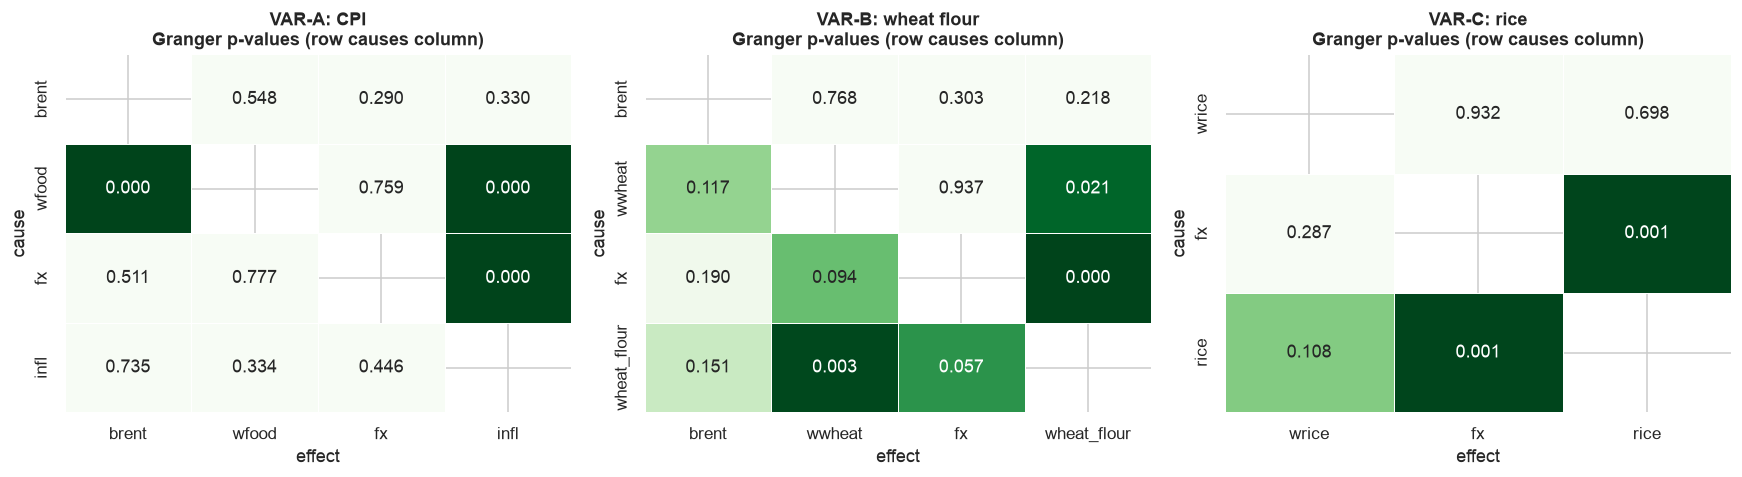

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, V) in zip(axes, [("VAR-A: CPI", VA), ("VAR-B: wheat flour", VB), ("VAR-C: rice", VC)]):
    pm = V.granger.pivot(index="cause", columns="effect", values="p").reindex(index=V.data.columns, columns=V.data.columns)
    sns.heatmap(pm, annot=True, fmt=".3f", cmap="Greens_r", vmin=0, vmax=0.2, cbar=False, ax=ax,
                mask=pm.isna(), linewidths=0.5)
    ax.set_title(f"{name}\nGranger p-values (row causes column)"); ax.set_xlabel("effect"); ax.set_ylabel("cause")
fig.tight_layout(); save(fig, "16_granger_pvalues")
gr = pd.concat([V.granger.assign(model=n) for n, V in [("VAR-A", VA), ("VAR-B", VB), ("VAR-C", VC)]])
gr.to_csv(TAB / "phase3_granger_var.csv", index=False)
display(gr[gr["effect"].isin(["infl", "wheat_flour", "rice", "fx"])].round(3))

,model,shock,response,shock_1sd_%,cum_resp_3m,cum_resp_12m,se_12m,implied_elasticity_12m,significant_12m
0,VAR-A,fx,infl,1.859,1.418,1.247,0.238,0.670,True
1,VAR-A,wfood,infl,2.725,0.826,0.832,0.278,0.305,True
2,VAR-A,brent,infl,8.495,0.251,0.320,0.825,0.038,False
3,VAR-B,fx,wheat_flour,1.673,0.842,0.660,0.302,0.395,True
4,VAR-B,wwheat,wheat_flour,7.223,1.666,1.972,1.417,0.273,False
5,VAR-B,brent,wheat_flour,8.457,0.419,0.524,1.936,0.062,False
6,VAR-C,fx,rice,1.808,-0.692,0.104,0.247,0.058,False
7,VAR-C,wrice,rice,3.800,-0.827,-0.480,0.529,-0.126,False


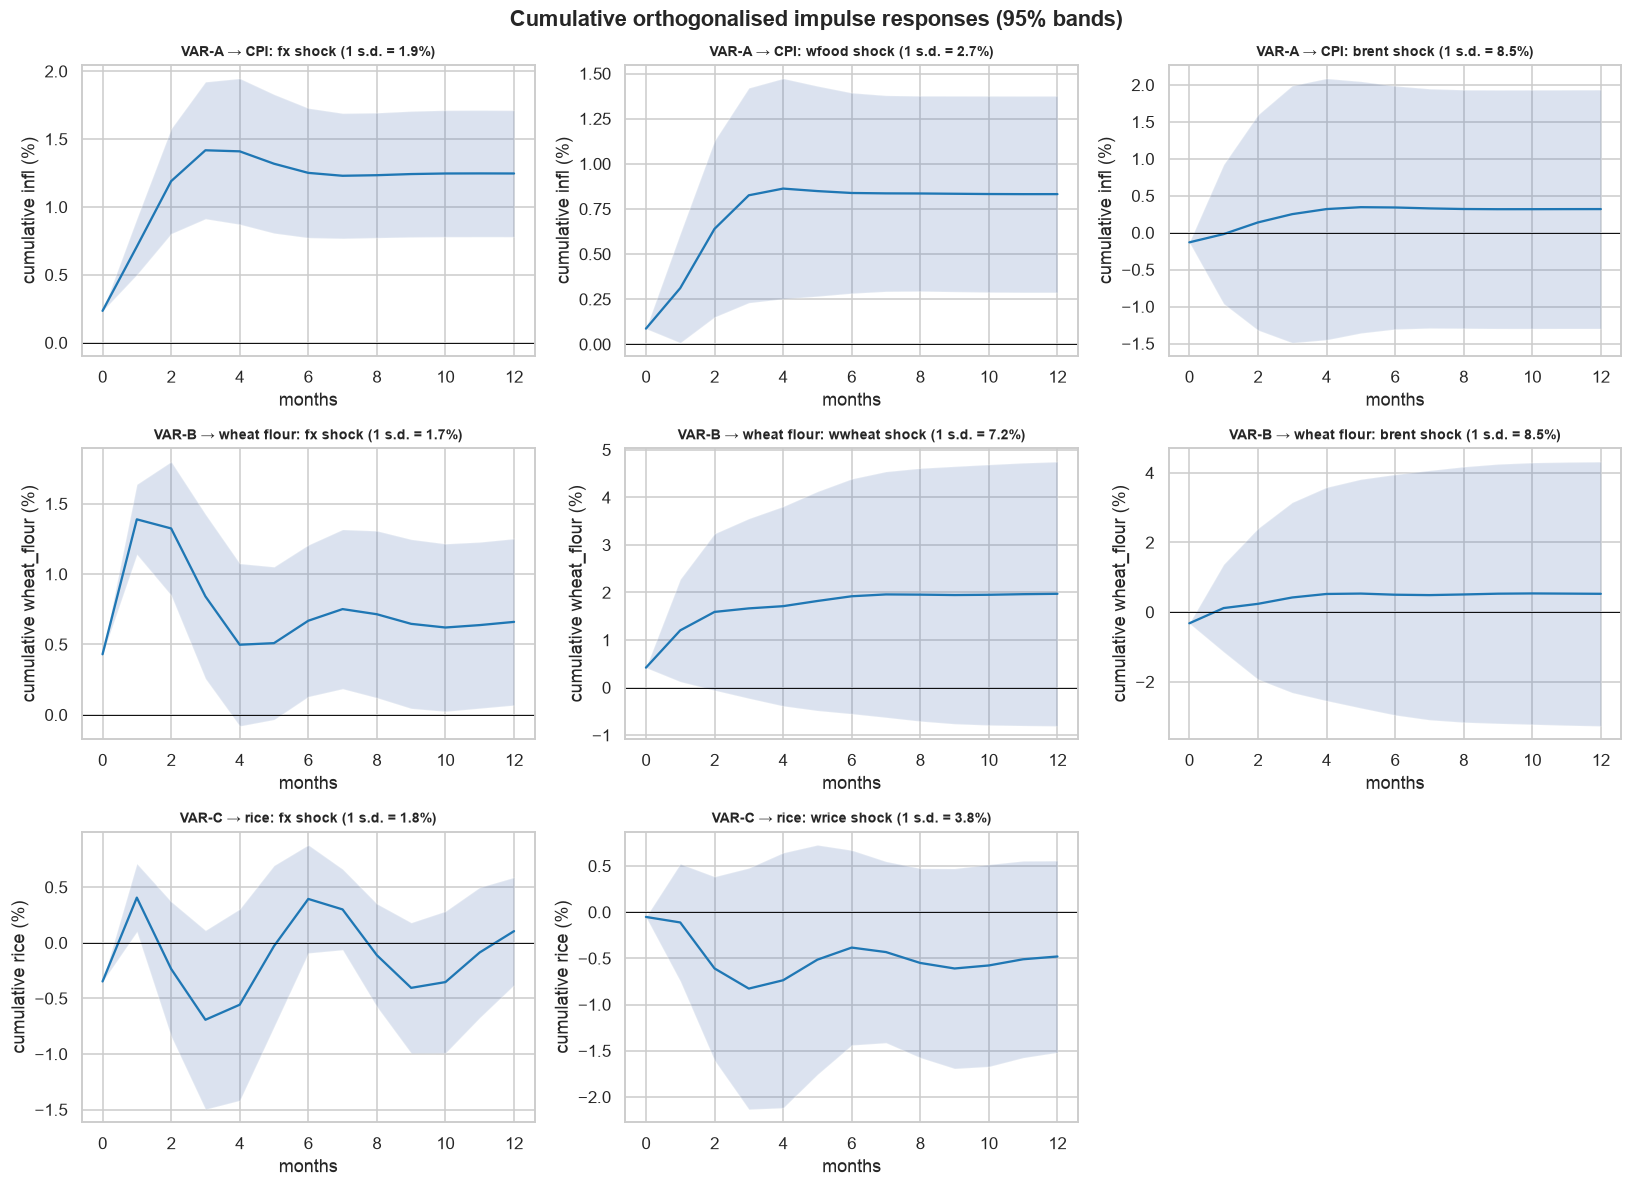

In [9]:
def cum_irf(V, impulse, response, steps=12):
    irf = V.results.irf(steps)
    names = list(V.data.columns)
    i, j = names.index(response), names.index(impulse)
    eff = irf.orth_cum_effects[:, i, j]
    se = np.sqrt([c[i * len(names) + j, i * len(names) + j] for c in irf.cum_effect_cov(orth=True)])
    return eff, se

def irf_panel(V, response, impulses, title, ax_row):
    for ax, imp in zip(ax_row, impulses):
        eff, se = cum_irf(V, imp, response)
        h = np.arange(len(eff))
        ax.plot(h, eff, color="tab:blue"); ax.fill_between(h, eff - 1.96 * se, eff + 1.96 * se, alpha=0.2)
        ax.axhline(0, color="black", lw=0.6)
        sd = V.results.resid[imp].std()
        ax.set_title(f"{title}: {imp} shock (1 s.d. = {sd:.1f}%)", fontsize=9)
        ax.set_xlabel("months"); ax.set_ylabel(f"cumulative {response} (%)")

fig, axes = plt.subplots(3, 3, figsize=(15, 11))
irf_panel(VA, "infl", ["fx", "wfood", "brent"], "VAR-A → CPI", axes[0])
irf_panel(VB, "wheat_flour", ["fx", "wwheat", "brent"], "VAR-B → wheat flour", axes[1])
irf_panel(VC, "rice", ["fx", "wrice"], "VAR-C → rice", axes[2][:2])
axes[2][2].axis("off")
fig.suptitle("Cumulative orthogonalised impulse responses (95% bands)", fontweight="bold")
fig.tight_layout(); save(fig, "17_irf")

rows = []
for name, V, resp, imps in [("VAR-A", VA, "infl", ["fx", "wfood", "brent"]),
                             ("VAR-B", VB, "wheat_flour", ["fx", "wwheat", "brent"]),
                             ("VAR-C", VC, "rice", ["fx", "wrice"])]:
    for imp in imps:
        eff, se = cum_irf(V, imp, resp)
        sd = V.results.resid[imp].std()
        rows.append({"model": name, "shock": imp, "response": resp, "shock_1sd_%": sd,
                     "cum_resp_3m": eff[3], "cum_resp_12m": eff[12], "se_12m": se[12],
                     "implied_elasticity_12m": eff[12] / sd, "significant_12m": abs(eff[12]) > 1.96 * se[12]})
irf_tab = pd.DataFrame(rows); irf_tab.to_csv(TAB / "phase3_irf_summary.csv", index=False)
display(irf_tab.round(3))

In [10]:
# Sample C (2023–2026): only 45 monthly changes, so bivariate Granger tests (lags 1–3) instead of a VAR
rows = []
tests = [("ΔLKR/USD", D("lkr_per_usd"), t, D(c)) for t, c in [("sugar", "cbsl_sugar"), ("red dhal", "cbsl_dhal"),
          ("big onion (imp)", "cbsl_big_onion_imp"), ("potato (imp)", "cbsl_potato_imp"), ("coconut", "cbsl_coconut"),
          ("rice Nadu", "cbsl_rice_nadu")]]
tests += [("ΔWorld sugar", D("world_sugar_usd_lb"), "sugar", D("cbsl_sugar")),
          ("ΔWorld rice", D("world_rice_usd_mt"), "rice Nadu", D("cbsl_rice_nadu")),
          ("ΔWorld coconut oil", D("world_coconut_oil_usd_mt"), "coconut", D("cbsl_coconut"))]
for dn, x, tn, y in tests:
    g = R.bivariate_granger(x.loc[recent], y.loc[recent], maxlag=3)
    rows.append({"cause": dn, "effect": tn, "n": int(g["n"].iloc[0]), "p_lag1": g.loc[1, "p"], "p_lag2": g.loc[2, "p"],
                 "p_lag3": g.loc[3, "p"], "min_p": g["p"].min()})
gC = pd.DataFrame(rows); gC.to_csv(TAB / "phase3_granger_recent.csv", index=False)
display(gC.round(3))

,cause,effect,n,p_lag1,p_lag2,p_lag3,min_p
0,ΔLKR/USD,sugar,45,0.834,0.431,0.117,0.117
1,ΔLKR/USD,red dhal,45,0.307,0.635,0.004,0.004
2,ΔLKR/USD,big onion (imp),45,0.422,0.579,0.719,0.422
3,ΔLKR/USD,potato (imp),45,0.154,0.082,0.319,0.082
4,ΔLKR/USD,coconut,45,0.571,0.860,0.851,0.571
5,ΔLKR/USD,rice Nadu,45,0.642,0.187,0.093,0.093
6,ΔWorld sugar,sugar,45,0.039,0.066,0.049,0.039
7,ΔWorld rice,rice Nadu,45,0.381,0.631,0.908,0.381
8,ΔWorld coconut oil,coconut,45,0.156,0.359,0.528,0.156


## 5. Pass-through regressions

Distributed-lag models in monthly log-changes, with HAC (Newey-West) standard errors:

$$\Delta p_t = \alpha + \sum_{k=0}^{K} \beta_k \,\Delta x_{t-k} + \gamma' \text{controls}_t + \varepsilon_t$$

The **cumulative pass-through** after K months is $\sum_k \beta_k$, tested jointly. A value of 1 means full pass-through.

### 5a. Exchange rate → CPI, and the post-float regime

In [11]:
fx = D("lkr_per_usd")
cpi_drivers = {"fx": fx, "fx × post_float": fx * df["post_float"], "world food": D("world_food_price_index"),
               "brent": D("world_brent_usd_bbl")}
ctrl = df[["covid", "crisis", "ccpi_basis"]]
specs = {
    "full 2000–2026 (interaction)": R.passthrough(df["inflation_mom_pct"], cpi_drivers, 6, ctrl, month_fe=True),
    "pre-float 2000–2022-02": R.passthrough(df["inflation_mom_pct"].loc[:"2022-02"],
                                           {k: v for k, v in cpi_drivers.items() if k != "fx × post_float"}, 6,
                                           df[["covid"]], month_fe=True),
    "NCPI-basis only (to 2023-11)": R.passthrough(df["inflation_mom_pct"].loc[:"2023-11"], cpi_drivers, 6,
                                                  df[["covid", "crisis"]], month_fe=True),
}
cpi_tab = pd.concat({k: v.cumulative.assign(n=v.n, sample=v.sample) for k, v in specs.items()})
display(cpi_tab.round(3))
full = specs["full 2000–2026 (interaction)"].model
# Post-float total = fx + interaction, tested jointly using their covariance
names = list(full.params.index)
r = np.array([1.0 if (n.startswith("fx_L") or n.startswith("fx × post_float_L")) else 0.0 for n in names])
t = full.t_test(r)
print(f"Cumulative 6-month FX pass-through to CPI AFTER the float: {float(np.squeeze(t.effect)):.3f} "
      f"(se {float(np.squeeze(t.sd)):.3f}, p {float(np.squeeze(t.pvalue)):.4f})")

impact (lag 0)  cumulative 0..6    se     p  long-run (with AR term)    n            sample
                             driver                                                                                                      
full 2000–2026 (interaction) fx                        0.216            0.295 0.115 0.010                      NaN  313  2000-08..2026-08
                             fx × post_float          -0.121            0.282 0.121 0.020                      NaN  313  2000-08..2026-08
                             world food                0.038            0.287 0.085 0.001                      NaN  313  2000-08..2026-08
                             brent                    -0.006           -0.006 0.028 0.836                      NaN  313  2000-08..2026-08
pre-float 2000–2022-02       fx                        0.209            0.268 0.117 0.022                      NaN  259  2000-08..2022-02
                             world food                0.036            0.269 0.090 0.003                      NaN  259  2000-08..2022-02
                             brent                    -0.006           -0.008 0.030 0.800                      NaN  259  2000-08..2022-02
NCPI-basis only (to 2023-11) fx                        0.214            0.292 0.115 0.011                      NaN  280  2000-08..2023-11
                             fx × post_float          -0.111            0.267 0.122 0.028                      NaN  280  2000-08..2023-11
                             world food                0.034            0.303 0.088 0.001                      NaN  280  2000-08..2023-11
                             brent                    -0.007           -0.014 0.029 0.629                      NaN  280  2000-08..2023-11

Cumulative 6-month FX pass-through to CPI AFTER the float: 0.577 (se 0.045, p 0.0000)


### 5b. World benchmark and exchange rate → wheat flour and rice (long WFP sample)

In [12]:
long_pt = {
    "wheat flour (2006–2022-06)": R.passthrough(D("wfp_wheat_flour").loc["2006-02":"2022-06"],
        {"world (USD)": D("world_wheat_usd_mt"), "fx": fx}, 6, df[["covid", "crisis"]]),
    "rice white (2010–2022-06)": R.passthrough(D("wfp_rice_white").loc["2010-06":"2022-06"],
        {"world (USD)": D("world_rice_usd_mt"), "fx": fx}, 6, df[["covid", "crisis"]]),
}
display(pd.concat({k: v.cumulative.assign(n=v.n, sample=v.sample) for k, v in long_pt.items()}).round(3))

levels = pd.DataFrame({
    "wheat flour vs world wheat × FX": R.long_run_levels(df["wfp_wheat_flour"].loc["2006-01":"2022-06"],
                                                          df["world_wheat_lkr"].loc["2006-01":"2022-06"]),
    "rice white vs world rice × FX": R.long_run_levels(df["wfp_rice_white"].loc["2010-05":"2022-06"],
                                                        df["world_rice_lkr"].loc["2010-05":"2022-06"]),
}).T
display(levels)

impact (lag 0)  cumulative 0..6    se     p  long-run (with AR term)    n            sample
                           driver                                                                                                  
wheat flour (2006–2022-06) world (USD)           0.053            0.379 0.098 0.000                      NaN  197  2006-02..2022-06
                           fx                    0.251            0.671 0.256 0.009                      NaN  197  2006-02..2022-06
rice white (2010–2022-06)  world (USD)           0.020           -0.092 0.245 0.706                      NaN  139  2010-12..2022-06
                           fx                   -0.173           -0.294 0.501 0.557                      NaN  139  2010-12..2022-06

,n,sample,long_run_elasticity,r2,engle_granger_p,cointegrated_5%
wheat flour vs world wheat × FX,198,2006-01..2022-06,0.651,0.551,0.230,False
rice white vs world rice × FX,146,2010-05..2022-06,0.910,0.437,0.848,False


### 5c. Recent CBSL sample (2023–2026): sugar, dhal, onion, potato, coconut, rice

In [13]:
rc = slice("2023-02-01", "2026-10-01")
recent_pt = {}
for name, col, world in [("sugar", "cbsl_sugar", "world_sugar_usd_lb"), ("rice Nadu", "cbsl_rice_nadu", "world_rice_usd_mt"),
                         ("coconut", "cbsl_coconut", "world_coconut_oil_usd_mt"), ("red dhal", "cbsl_dhal", None),
                         ("big onion (imp)", "cbsl_big_onion_imp", None), ("potato (imp)", "cbsl_potato_imp", None)]:
    drv = {"fx": fx}
    if world:
        drv["world (USD)"] = D(world)
    recent_pt[name] = R.passthrough(D(col).loc[rc], drv, 3)
display(pd.concat({k: v.cumulative.assign(n=v.n, sample=v.sample) for k, v in recent_pt.items()}).round(3))

impact (lag 0)  cumulative 0..3    se     p  long-run (with AR term)   n            sample
                driver                                                                                                 
sugar           fx                    0.620            0.573 0.332 0.085                      NaN  45  2023-02..2026-10
                world (USD)           0.134            0.373 0.145 0.010                      NaN  45  2023-02..2026-10
rice Nadu       fx                    0.074            0.160 0.154 0.297                      NaN  45  2023-02..2026-10
                world (USD)          -0.043           -0.068 0.102 0.509                      NaN  45  2023-02..2026-10
coconut         fx                   -0.429            0.201 0.404 0.619                      NaN  45  2023-02..2026-10
                world (USD)          -0.046            0.369 0.380 0.332                      NaN  45  2023-02..2026-10
red dhal        fx                    0.227            1.154 0.561 0.040                      NaN  45  2023-02..2026-10
big onion (imp) fx                    0.747            2.995 1.687 0.076                      NaN  45  2023-02..2026-10
potato (imp)    fx                    1.245           -0.410 0.469 0.382                      NaN  45  2023-02..2026-10

### 5d. Fuel cost → retail diesel

In [14]:
diesel = R.passthrough(D("fuel_auto_diesel"), {"brent (LKR)": D("world_brent_lkr")}, 2)
display(diesel.cumulative.assign(n=diesel.n, sample=diesel.sample).round(3))
print("Pooled sample: WFP 2015-10 → 2018-03 and scattered DCS/CPC months 2023 → 2026 (unflagged only).")

,impact (lag 0),cumulative 0..2,se,p,long-run (with AR term),n,sample
driver,,,,,,,
brent (LKR),0.013,0.412,0.198,0.037,NaN,47,2015-10..2026-10


Pooled sample: WFP 2015-10 → 2018-03 and scattered DCS/CPC months 2023 → 2026 (unflagged only).


,group,label,driver,elasticity,se,p,n,sample,horizon
0,CPI,"CPI ← FX, post-float",fx+interaction,0.577,0.045,0.000,313,2000-08..2026-08,cumulative 0..6
1,CPI,"CPI ← FX, pre-float",fx,0.268,0.117,0.022,259,2000-08..2022-02,cumulative 0..6
2,CPI,CPI ← world food,world food,0.287,0.085,0.001,313,2000-08..2026-08,cumulative 0..6
3,CPI,CPI ← Brent (USD),brent,-0.006,0.028,0.836,313,2000-08..2026-08,cumulative 0..6
4,Long WFP,Wheat flour ← world wheat,world (USD),0.379,0.098,0.000,197,2006-02..2022-06,cumulative 0..6
5,Long WFP,Wheat flour ← FX,fx,0.671,0.256,0.009,197,2006-02..2022-06,cumulative 0..6
6,Long WFP,Rice ← world rice,world (USD),-0.092,0.245,0.706,139,2010-12..2022-06,cumulative 0..6
7,Long WFP,Rice ← FX,fx,-0.294,0.501,0.557,139,2010-12..2022-06,cumulative 0..6
8,Recent CBSL,sugar ← world,world (USD),0.373,0.145,0.010,45,2023-02..2026-10,cumulative 0..3
9,Recent CBSL,rice Nadu ← world,world (USD),-0.068,0.102,0.509,45,2023-02..2026-10,cumulative 0..3


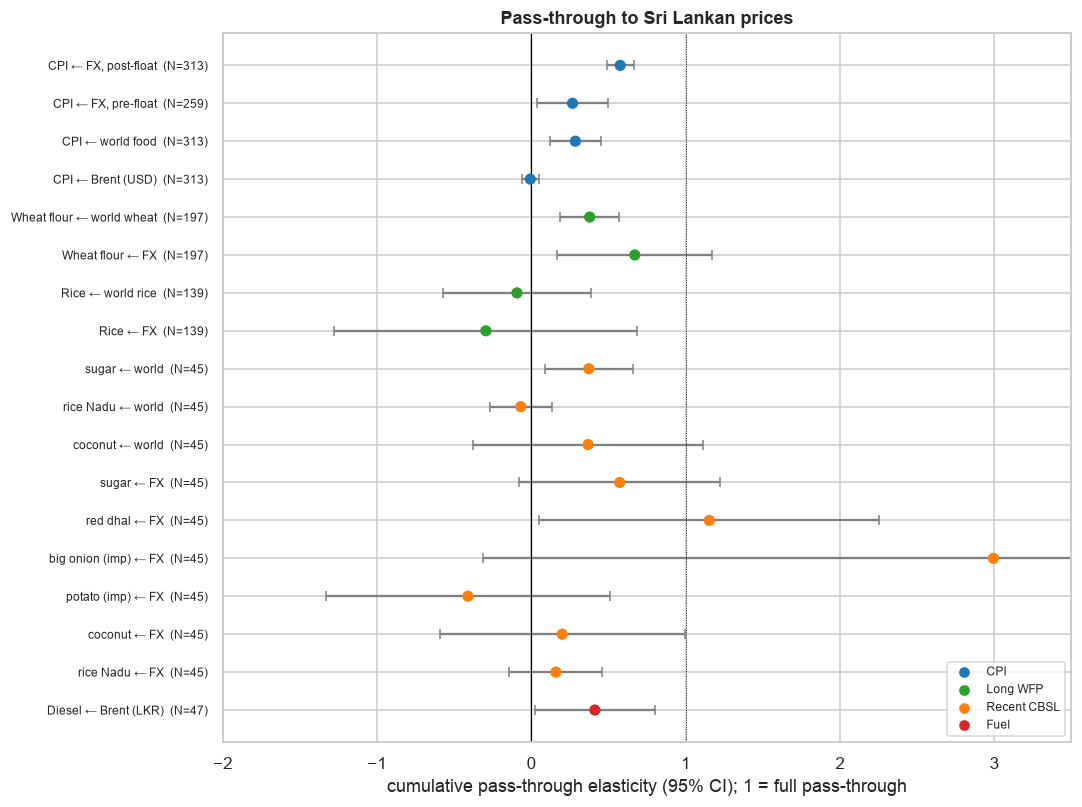

In [15]:
# Summary: cumulative pass-through elasticities with 95% CIs
rows = []
def add(group, label, pt, driver):
    c = pt.cumulative.loc[driver]
    rows.append({"group": group, "label": label, "driver": driver, "elasticity": c.iloc[1], "se": c["se"],
                 "p": c["p"], "n": pt.n, "sample": pt.sample, "horizon": c.index[1]})
add("CPI", "CPI ← FX, pre-float", specs["pre-float 2000–2022-02"], "fx")
add("CPI", "CPI ← world food", specs["full 2000–2026 (interaction)"], "world food")
add("CPI", "CPI ← Brent (USD)", specs["full 2000–2026 (interaction)"], "brent")
add("Long WFP", "Wheat flour ← world wheat", long_pt["wheat flour (2006–2022-06)"], "world (USD)")
add("Long WFP", "Wheat flour ← FX", long_pt["wheat flour (2006–2022-06)"], "fx")
add("Long WFP", "Rice ← world rice", long_pt["rice white (2010–2022-06)"], "world (USD)")
add("Long WFP", "Rice ← FX", long_pt["rice white (2010–2022-06)"], "fx")
for k in ["sugar", "rice Nadu", "coconut"]:
    add("Recent CBSL", f"{k} ← world", recent_pt[k], "world (USD)")
for k in ["sugar", "red dhal", "big onion (imp)", "potato (imp)", "coconut", "rice Nadu"]:
    add("Recent CBSL", f"{k} ← FX", recent_pt[k], "fx")
add("Fuel", "Diesel ← Brent (LKR)", diesel, "brent (LKR)")
summ = pd.DataFrame(rows)
post_eff = float(np.squeeze(t.effect)); post_se = float(np.squeeze(t.sd))
summ = pd.concat([pd.DataFrame([{"group": "CPI", "label": "CPI ← FX, post-float", "driver": "fx+interaction",
                                 "elasticity": post_eff, "se": post_se, "p": float(np.squeeze(t.pvalue)),
                                 "n": specs["full 2000–2026 (interaction)"].n,
                                 "sample": specs["full 2000–2026 (interaction)"].sample, "horizon": "cumulative 0..6"}]),
                  summ], ignore_index=True)
summ.to_csv(TAB / "phase3_passthrough_summary.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 7.5))
s = summ.iloc[::-1].reset_index(drop=True)
colors = s["group"].map({"CPI": "tab:blue", "Long WFP": "tab:green", "Recent CBSL": "tab:orange", "Fuel": "tab:red"})
ax.errorbar(s["elasticity"], range(len(s)), xerr=1.96 * s["se"], fmt="none", ecolor="grey", capsize=3)
ax.scatter(s["elasticity"], range(len(s)), c=colors, zorder=3, s=40)
ax.set_yticks(range(len(s))); ax.set_yticklabels([f"{l}  (N={n})" for l, n in zip(s["label"], s["n"])], fontsize=8)
ax.axvline(0, color="black", lw=0.8); ax.axvline(1, color="black", lw=0.6, ls=":")
ax.set_xlim(-2, 3.5)
ax.set_xlabel("cumulative pass-through elasticity (95% CI); 1 = full pass-through")
ax.set_title("Pass-through to Sri Lankan prices")
for g, c in {"CPI": "tab:blue", "Long WFP": "tab:green", "Recent CBSL": "tab:orange", "Fuel": "tab:red"}.items():
    ax.scatter([], [], c=c, label=g)
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout(); save(fig, "18_passthrough_forest")
display(summ.round(3))

## 6. Key findings

**Exchange rate → CPI (strongest, most robust result)**
- **Lead/lag:** LKR/USD changes lead monthly CPI inflation by **1–2 months** (peak r = 0.51 at lag 1, N = 318).
- **Pass-through after 6 months:** **≈ 0.27 before the float** and **≈ 0.58 after March 2022**. The post-float increase is significant (interaction p = 0.02).
- **VAR-A:** FX strongly Granger-causes inflation (p < 0.001), and a 1-s.d. (1.9%) depreciation raises the price level by ≈1.25% within 12 months (elasticity ≈ 0.67).
- **Robustness:** results are unchanged on the NCPI-basis sample only (to 2023-11), so the CPI splice doesn't drive them.

**World food prices → CPI:** cumulative pass-through **≈ 0.29** (p = 0.001), arriving with a 1–3 month lag.

**Fuel**
- **World oil → CPI:** no detectable direct pass-through from Brent (≈0), consistent with administered domestic fuel prices.
- **Retail diesel:** follows **Brent in LKR with a 1-month lag** (r = 0.47 pooled N = 48; 0.74 in 2023–26 N = 25), with cumulative elasticity ≈ 0.41 (p = 0.04), consistent with monthly formula pricing. The sample is small and gappy.

**Wheat flour (2006–2022-06):** passes through both world wheat (**≈ 0.38**) and the exchange rate (**≈ 0.67**) within 6 months, and both Granger-cause it. The series ends at the crisis peak.

**Rice: no pass-through.** World rice and FX have no significant cumulative effect on domestic rice, in either the long WFP sample or the recent CBSL sample, and levels are not cointegrated with import parity. FX "Granger-causes" rice in VAR-C, but rice also "causes" FX and the impulse response oscillates around zero, which points to crisis co-movement rather than pass-through. This fits a protected/administered rice market and the widening local–world gap seen in Phase 2.

**Recent CBSL items (2023–26, N = 45; low power)**
- **Sugar:** follows **world sugar** (≈ 0.37, p = 0.01; Granger p = 0.04). FX ≈ 0.57 (p = 0.09).
- **Red dhal:** responds to **FX** (≈ 1.15 over 3 months, p = 0.04; Granger p = 0.004 at lag 3) and to Brent-in-LKR (r = 0.54 at lag 1, which suggests freight/transport cost effects).
- **Big onion (imported):** large but imprecise FX effect (≈ 3.0, p = 0.08).
- **Not driven by FX or world prices:** coconut, imported potato and Nadu rice. Coconut is a domestic crop and is driven by local supply.

**Caveats**
- **Sample size:** recent-sample results use 45 months and best-lag correlations are selected after the fact, so expect some false positives.
- **VAR diagnostics:** VAR-A residuals are not white, and all VARs have fat-tailed (non-normal) residuals from the crisis, so impulse-response bands are approximate.
- **Granger ≠ causation:** reverse links such as "wheat flour → world wheat" are common-shock artefacts.
- **Data gaps:** wheat flour ends 2022-06, WFP sugar never overlaps CBSL sugar, and fuel data is gappy.